# DA3 project November 2026

Supervisor: Nicolas Catz

Authors: Benjamin Mellet, Eliana Charah, Lena Mollon, Arthur Lesle, Zoe Andreo

### Loading libraries and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from scipy.io import loadmat
from pathlib import Path
from matplotlib.patches import Rectangle
import re
import os


if os.getcwd().endswith('scripts'):
    os.chdir('..')
os.getcwd()

'/Users/arthur/git/Master amu/DA3/DA3_VSDI_S1_G1_2026'

In [2]:
current_dir = Path.cwd()
folder = current_dir.parent
data_folder = folder / 'data'

## 1. Data pre-processing

In [4]:
## load the condition
## condition is the order of the finger stimulations

condition_load = np.load(data_folder / 'New_list_conditions.npy')
condition = []

for i in condition_load[0::2]:
    cond = re.split('_', str(i))[0]
    condition.append(cond[-1])

condition = np.array(condition)

In [6]:
## extract data from trials
sig = 1

Cortex = np.load(data_folder / 'Image_Cortex.npy')  
x = np.arange(1, 31, 1)

delta_f = []

for trial_num in x:
    stim = np.load(data_folder / f'Trial_{trial_num}_Stim.npy')
    control = np.load(data_folder / f'Trial_{trial_num}_Control.npy')

    df = (stim - control)/control
    delta_f.append(df)

delta_f = np.array(delta_f)

df_filtered = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, 0)) 

In [7]:
cond1_index = np.where(condition == '1')[0]
cond2_index = np.where(condition == '2')[0]
cond3_index = np.where(condition == '3')[0]

In [8]:
## filter before or after taking mean?

cond1_ave = np.mean(df_filtered[cond1_index], axis=0)
cond2_ave = np.mean(df_filtered[cond2_index], axis=0)
cond3_ave = np.mean(df_filtered[cond3_index], axis=0)

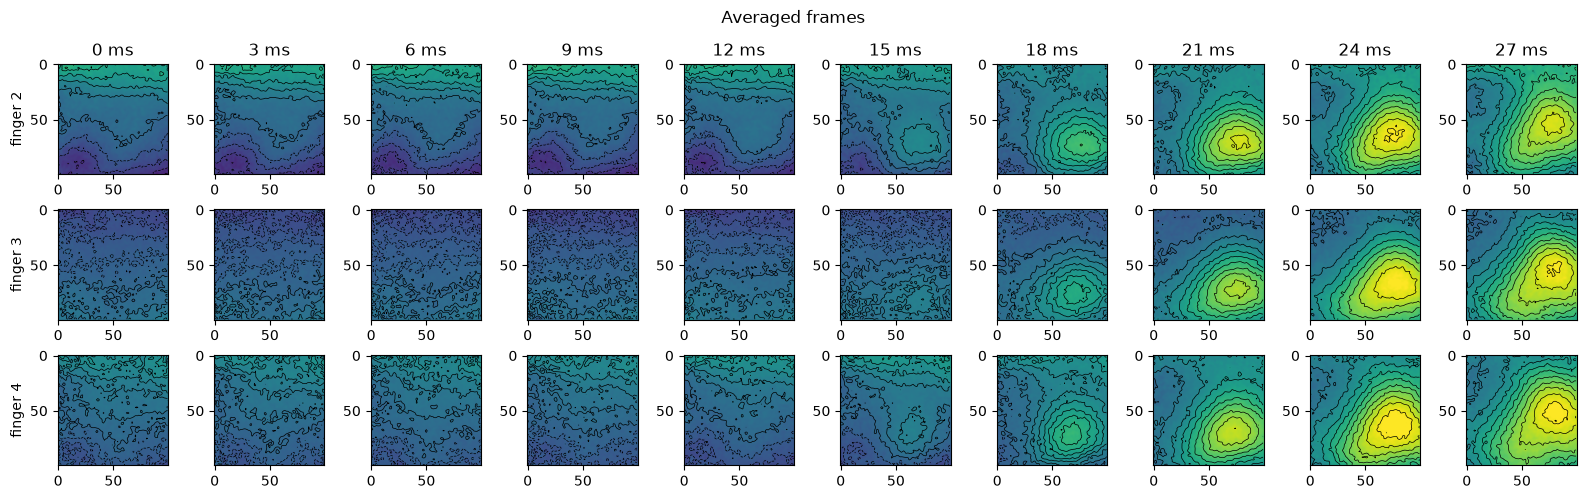

In [12]:
fig, ax = plt.subplots(3, 10, figsize=(16,5))

vmin = np.min(cond1_ave)
vmax=np.max(cond1_ave)

level=10

for i in range(10):
    ax[0][i].imshow(cond1_ave[:,:,33+i], vmin=vmin, vmax=vmax)
    ax[1][i].imshow(cond2_ave[:,:,33+i], vmin=vmin, vmax=vmax)
    ax[2][i].imshow(cond3_ave[:,:,33+i], vmin=vmin, vmax=vmax)

    ax[0][i].contour(cond1_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[1][i].contour(cond2_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[2][i].contour(cond3_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')

    ax[0][i].set_title(f'{i*3} ms')

ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

fig.suptitle('Averaged frames')
plt.tight_layout()

In [13]:
cond1_max = cond1_ave[:,:,33:40].max()
cond2_max = cond2_ave[:,:,33:40].max()
cond3_max = cond3_ave[:,:,33:40].max()

In [14]:
thresh = 0.85

cond1_thresh = np.where(cond1_ave > cond1_max * thresh, cond1_ave, 0)
cond2_thresh = np.where(cond2_ave > cond2_max * thresh, cond1_ave, 0)
cond3_thresh = np.where(cond3_ave > cond3_max * thresh, cond1_ave, 0)

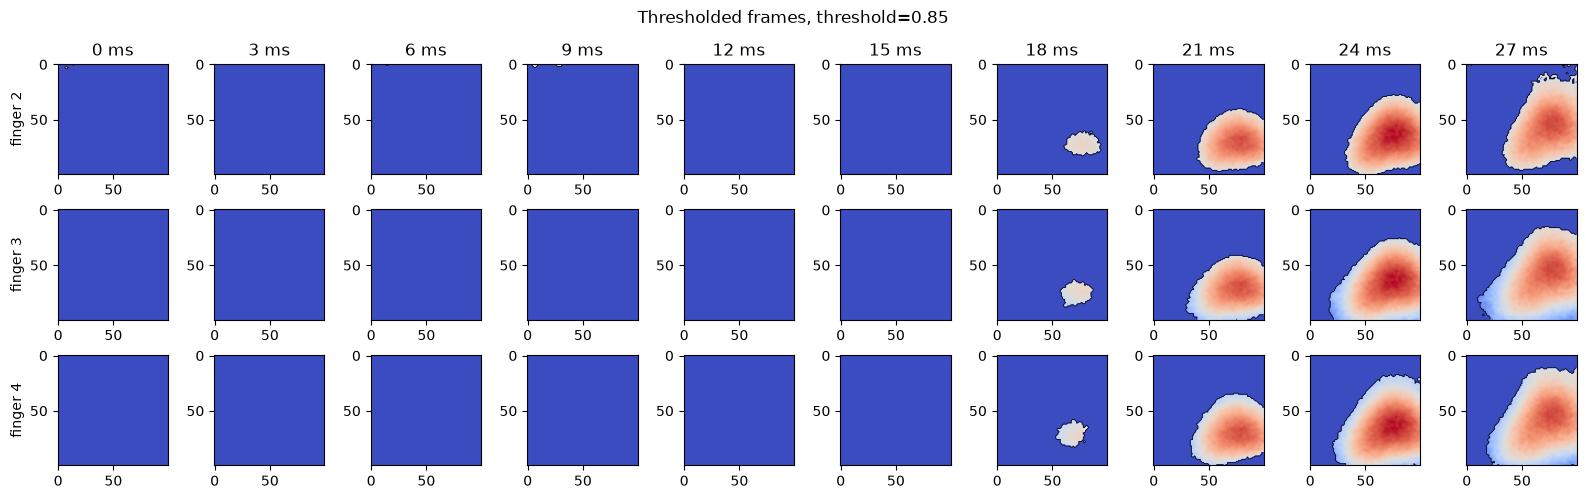

In [17]:
fig, ax = plt.subplots(3, 10, figsize=(16,5))

vmin = np.min(cond1_thresh)
vmax=np.max(cond1_thresh)

level=0

for i in range(10):
    ax[0][i].imshow(cond1_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')
    ax[1][i].imshow(cond2_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')
    ax[2][i].imshow(cond3_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')

    ax[0][i].contour(cond1_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[1][i].contour(cond2_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[2][i].contour(cond3_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')

    ax[0][i].set_title(f'{i*3} ms')

ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

fig.suptitle(f'Thresholded frames, threshold={thresh}')
plt.tight_layout()

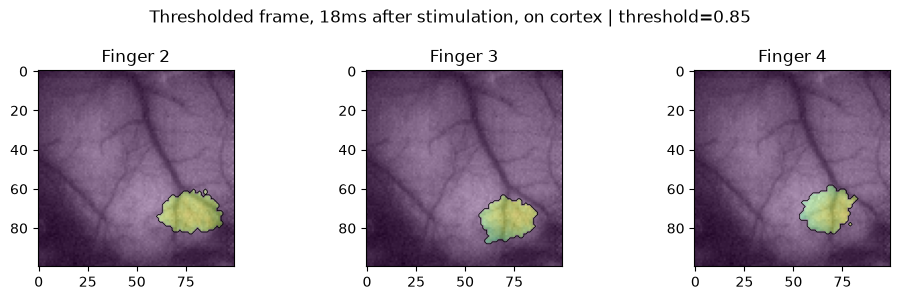

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
frame = 39 # ie., 18ms after stimulation

ax[0].imshow(Cortex, alpha=0.6)
ax[1].imshow(Cortex, alpha=0.6)
ax[2].imshow(Cortex, alpha=0.6)

ax[0].imshow(cond1_thresh[:,:,frame])
ax[1].imshow(cond2_thresh[:,:,frame])
ax[2].imshow(cond3_thresh[:,:,frame])

ax[0].contour(cond1_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')
ax[1].contour(cond2_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')
ax[2].contour(cond3_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')

ax[0].set_title('Finger 2')
ax[1].set_title('Finger 3')
ax[2].set_title('Finger 4')

fig.suptitle(f'Thresholded frame, {(frame-33)*3}ms after stimulation, on cortex | threshold={thresh}')
plt.tight_layout()

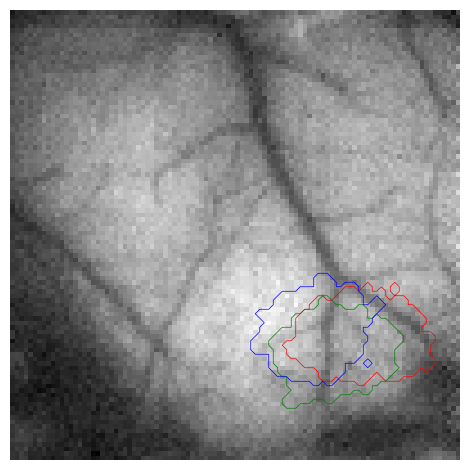

In [36]:
plt.imshow(Cortex)
cs1 = plt.contour(cond1_thresh[:,:,frame], levels=0, linewidths=0.5, colors='r')
cs2 = plt.contour(cond2_thresh[:,:,frame], levels=0, linewidths=0.5, colors='g')
cs3 = plt.contour(cond3_thresh[:,:,frame], levels=0, linewidths=0.5, colors='b')

plt.axis('off')
plt.tight_layout()

- The red contour represent finger 2
- The green contour represents finger 3
- The blue contour represents finger 4

## 2. Testing different methods to extract the somatopy

#### 1st method: Competition

As can be seen in the figure above, each finger occupies a region. However, these regions are highly overlapped. Therefore, our first instinct was to use apply a competition approach. That is, for each pixel in one region that overlaps a pixel from the other regions, the pixel that has the highest fluorescence 'wins' that pixel. Pixels were each region has the same fluorescence are considered as a tie and are not assigned to any particular region.

In [37]:
roi1 = cond1_thresh[40:,40:,39]
roi2 = cond2_thresh[40:,40:,39]
roi3 = cond3_thresh[40:,40:,39]

In [38]:
pixel_overlap = []
for i in range(60):
    row = []
    for j in range(60):
        if roi1[i][j] != 0 and roi2[i][j] != 0 and roi3[i][j] != 0:
            if roi1[i][j] > roi2[i][j] and roi1[i][j] > roi3[i][j]:
                row.append(1)
            elif roi2[i][j] > roi1[i][j] and roi2[i][j] > roi3[i][j]:
                row.append(2)
            elif roi3[i][j] > roi2[i][j] and roi3[i][j] > roi1[i][j]:
                row.append(3)
            else:
                row.append(4)
        else:
            row.append(0)
    pixel_overlap.append(row)

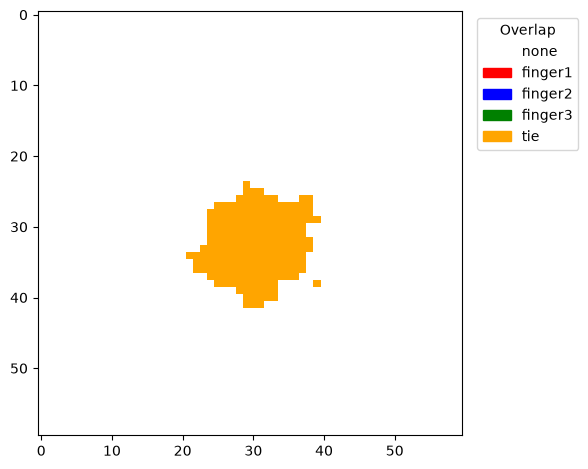

In [39]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

colors = ['white', 'red', 'blue', 'green', 'orange']
labels = ['none', 'finger1', 'finger2', 'finger3', 'tie']

cmap = ListedColormap(colors)

fig, ax = plt.subplots()
ax.imshow(np.array(pixel_overlap), cmap=cmap, vmin=0, vmax=4, interpolation='nearest')

handles = [mpatches.Patch(color=c, label=l) for c, l in zip(colors, labels)]
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', title='Overlap')

plt.tight_layout()
plt.show()

#### 2nd method: Contrasts

Seeing that the competition method did not work, we then tested a contrast method inspired from fMRI data analysis. The idea was to substract the mean relative 

In [21]:
d1_contrast = roi1 - np.mean([roi2, roi3], axis=0)
d2_contrast = roi2 - np.mean([roi1, roi3], axis=0)
d3_contrast = roi3 - np.mean([roi1, roi2], axis=0)

In [22]:
threshold=0.0
d1_contrast[d1_contrast < threshold] = 0
d2_contrast[d2_contrast < threshold] = 0
d3_contrast[d3_contrast < threshold] = 0

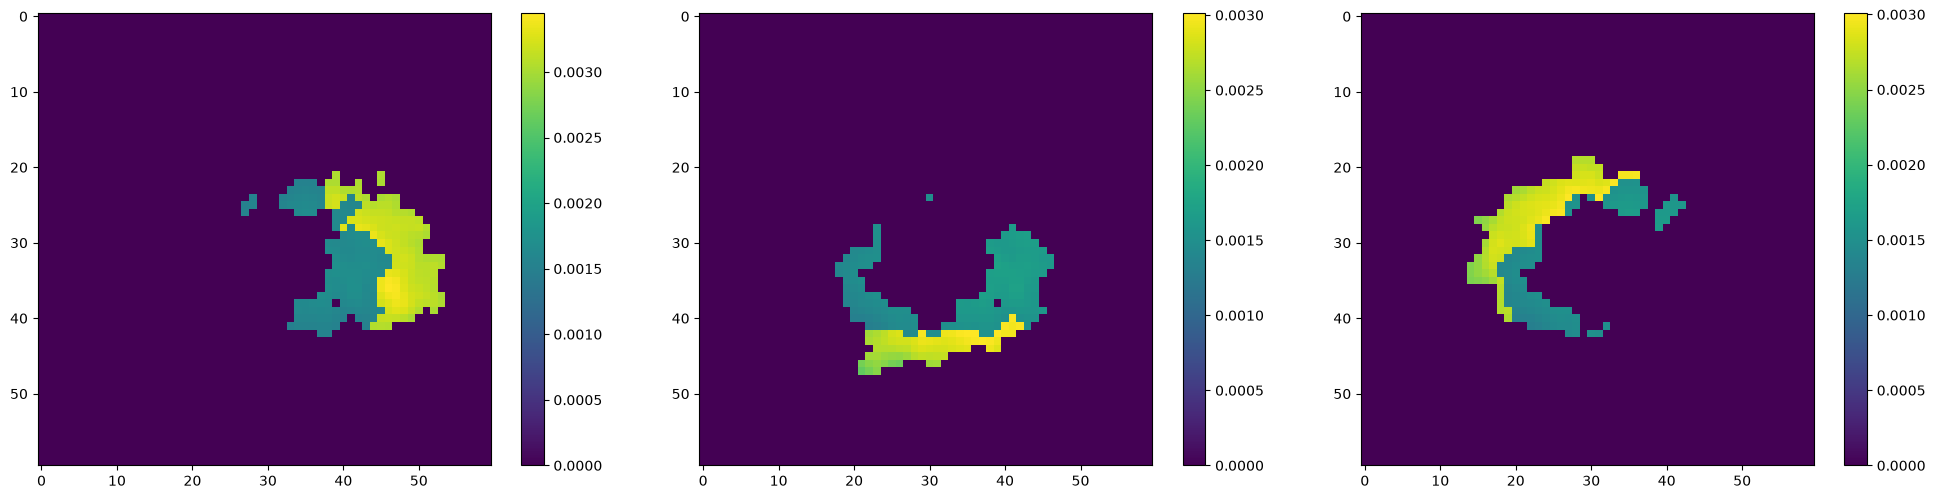

In [23]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))
im1 = ax1.imshow(d1_contrast)
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(d2_contrast)
fig.colorbar(im2, ax=ax2)

im3 = ax3.imshow(d3_contrast)
fig.colorbar(im3, ax=ax3)

plt.tight_layout()

#### 3rd method: Finding the center